In [1]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

In [2]:
df = pd.read_pickle(f"../datasets/Clustering.pkl")
df.head()

,experimenter,date,exp_num,raw_id,field,region,cond1,cond2,roi_id,preprocess_id_x_gChirp,...,os_index_movingbar,os_pvalue_movingbar,pref_or_movingbar,on_off_movingbar,d_qi_movingbar,dir_component_movingbar,time_component_movingbar,time_component_dt_movingbar,surrogate_v_movingbar,surrogate_dsi_movingbar
0,Salomon,2025-09-08,2,1,XY1,RR,v,C1,1,1,...,0.276144,0.29,1.251740,-0.30,0.424169,"[0.2692992, 0.21163529, 1.0, 0.0, 0.5561289, 0...","[0.26338604, -0.32434568, 0.50420314, 0.173609...",0.128,"[0.40229368, 0.0, 1.0, 0.22974569, 0.2547209, ...",0.099733
1,Salomon,2025-09-08,2,1,XY1,RR,v,C1,2,1,...,0.154824,0.58,2.867670,-0.06,0.573542,"[0.57404375, 0.5936899, 0.0, 0.09891763, 0.595...","[0.23134468, 0.12591584, -0.19623627, 0.122565...",0.128,"[0.71617424, 0.42367765, 0.0, 0.07766017, 0.33...",0.477601
2,Salomon,2025-09-08,2,1,XY1,RR,v,C1,3,1,...,0.483200,0.02,0.861053,-0.24,0.425207,"[0.35994393, 0.4662192, 0.58913016, 0.14168158...","[0.47586474, -0.5384664, -0.35983962, -0.44003...",0.128,"[0.3359132, 0.3226042, 0.47080025, 0.0, 0.3162...",0.222633
3,Salomon,2025-09-08,2,1,XY1,RR,v,C1,4,1,...,0.158540,0.43,0.351112,0.12,0.508752,"[0.05255287, 1.0, 0.0, 0.9599831, 0.82622796, ...","[-0.6013447, 0.066103116, 0.07772926, 0.050788...",0.128,"[0.35936928, 0.6933557, 0.0, 1.0, 0.77427435, ...",0.087994
4,Salomon,2025-09-08,2,1,XY1,RR,v,C1,5,1,...,0.059757,0.77,2.606700,-0.04,0.386349,"[0.09850365, 0.63157904, 0.0, 0.045831554, 0.4...","[0.06198706, 0.373452, 0.6631308, -0.64670223,...",0.128,"[0.2739429, 0.9214205, 0.08431966, 0.12541033,...",0.238921


In [3]:
df_c1 = df[df["cond2"] == "C1"]
df_c1.head()

,experimenter,date,exp_num,raw_id,field,region,cond1,cond2,roi_id,preprocess_id_x_gChirp,...,os_index_movingbar,os_pvalue_movingbar,pref_or_movingbar,on_off_movingbar,d_qi_movingbar,dir_component_movingbar,time_component_movingbar,time_component_dt_movingbar,surrogate_v_movingbar,surrogate_dsi_movingbar
0,Salomon,2025-09-08,2,1,XY1,RR,v,C1,1,1,...,0.276144,0.29,1.251740,-0.30,0.424169,"[0.2692992, 0.21163529, 1.0, 0.0, 0.5561289, 0...","[0.26338604, -0.32434568, 0.50420314, 0.173609...",0.128,"[0.40229368, 0.0, 1.0, 0.22974569, 0.2547209, ...",0.099733
1,Salomon,2025-09-08,2,1,XY1,RR,v,C1,2,1,...,0.154824,0.58,2.867670,-0.06,0.573542,"[0.57404375, 0.5936899, 0.0, 0.09891763, 0.595...","[0.23134468, 0.12591584, -0.19623627, 0.122565...",0.128,"[0.71617424, 0.42367765, 0.0, 0.07766017, 0.33...",0.477601
2,Salomon,2025-09-08,2,1,XY1,RR,v,C1,3,1,...,0.483200,0.02,0.861053,-0.24,0.425207,"[0.35994393, 0.4662192, 0.58913016, 0.14168158...","[0.47586474, -0.5384664, -0.35983962, -0.44003...",0.128,"[0.3359132, 0.3226042, 0.47080025, 0.0, 0.3162...",0.222633
3,Salomon,2025-09-08,2,1,XY1,RR,v,C1,4,1,...,0.158540,0.43,0.351112,0.12,0.508752,"[0.05255287, 1.0, 0.0, 0.9599831, 0.82622796, ...","[-0.6013447, 0.066103116, 0.07772926, 0.050788...",0.128,"[0.35936928, 0.6933557, 0.0, 1.0, 0.77427435, ...",0.087994
4,Salomon,2025-09-08,2,1,XY1,RR,v,C1,5,1,...,0.059757,0.77,2.606700,-0.04,0.386349,"[0.09850365, 0.63157904, 0.0, 0.045831554, 0.4...","[0.06198706, 0.373452, 0.6631308, -0.64670223,...",0.128,"[0.2739429, 0.9214205, 0.08431966, 0.12541033,...",0.238921


In [4]:
dates = df_c1["date"].unique()

for date in dates:

    df_date = df_c1[df_c1["date"] == date]
    fields = df_date["field"].unique()

    for field in fields:

        df_field = df_date[df_date["field"] == field]
        cond2 = df_field["cond2"].unique()

        df_field_filtered = df_field[df_field["qidx_gChirp"] > 0.35]

        print(f"{date}; {field}: Filtered: {len(df_field_filtered)}, All: {len(df_field)}, In %: {np.round(len(df_field_filtered)/len(df_field)*100, 0)}")

2025-09-08; XY1: Filtered: 6, All: 93, In %: 6.0
2025-09-08; XY2: Filtered: 61, All: 187, In %: 33.0
2025-09-08; XY3: Filtered: 84, All: 134, In %: 63.0
2025-09-08; XY4: Filtered: 8, All: 160, In %: 5.0
2025-09-08; XY6: Filtered: 28, All: 149, In %: 19.0
2025-09-08; XY7: Filtered: 246, All: 249, In %: 99.0
2025-09-08; XY8: Filtered: 221, All: 258, In %: 86.0
2025-10-23; XY7: Filtered: 147, All: 177, In %: 83.0
2025-10-23; XY8: Filtered: 13, All: 183, In %: 7.0
2025-10-23; XY1: Filtered: 1, All: 167, In %: 1.0
2025-10-23; XY2: Filtered: 71, All: 163, In %: 44.0
2025-10-23; XY3: Filtered: 25, All: 113, In %: 22.0
2025-10-23; XY4: Filtered: 189, All: 189, In %: 100.0
2025-10-23; XY5: Filtered: 177, All: 182, In %: 97.0
2025-10-23; XY6: Filtered: 154, All: 166, In %: 93.0
2025-11-19; XY4: Filtered: 187, All: 187, In %: 100.0
2025-11-19; XY5: Filtered: 0, All: 187, In %: 0.0


In [5]:
# Quality threshold for individual recordings
qidx_threshold = 0.35

# Minimum fraction of recordings that need to pass
quality_threshold = 0.30

# Calculate quality for each date-field pair
field_quality = (
    df_c1
    .assign(passes_quality=df_c1["qidx_gChirp"] > qidx_threshold)
    .groupby(["date", "field"])["passes_quality"]
    .mean()
)

# Keep only date-field pairs with >= 30% good recordings
good_fields = field_quality[field_quality >= quality_threshold].index

# Filter the original dataframe
df_c1_filtered = (
    df_c1.set_index(["date", "field"])
         .loc[good_fields]
         .reset_index()
)

print(f"Original rows: {len(df_c1)}")
print(f"Filtered rows: {len(df_c1_filtered)}")

Original rows: 2944
Filtered rows: 1892


In [9]:
df_c1_thresh = df_c1_filtered[df_c1_filtered["qidx_gChirp"] > 0.35]

In [6]:
print(df_c1_filtered.columns.tolist())

['date', 'field', 'experimenter', 'exp_num', 'raw_id', 'region', 'cond1', 'cond2', 'roi_id', 'preprocess_id_x_gChirp', 'average_gChirp', 'average_norm_gChirp', 'average_t0_gChirp', 'average_dt_gChirp', 'triggertimes_rel_gChirp', 'preprocess_id_y_gChirp', 'qidx_gChirp', 'min_qidx_gChirp', 'preprocess_id_x_lChirp', 'average_lChirp', 'average_norm_lChirp', 'average_t0_lChirp', 'average_dt_lChirp', 'triggertimes_rel_lChirp', 'preprocess_id_y_lChirp', 'qidx_lChirp', 'min_qidx_lChirp', 'preprocess_id_x_movingbar', 'average_movingbar', 'average_norm_movingbar', 'average_t0_movingbar', 'average_dt_movingbar', 'triggertimes_rel_movingbar', 'preprocess_id_y_movingbar', 'ds_index_movingbar', 'ds_pvalue_movingbar', 'pref_dir_movingbar', 'os_index_movingbar', 'os_pvalue_movingbar', 'pref_or_movingbar', 'on_off_movingbar', 'd_qi_movingbar', 'dir_component_movingbar', 'time_component_movingbar', 'time_component_dt_movingbar', 'surrogate_v_movingbar', 'surrogate_dsi_movingbar']


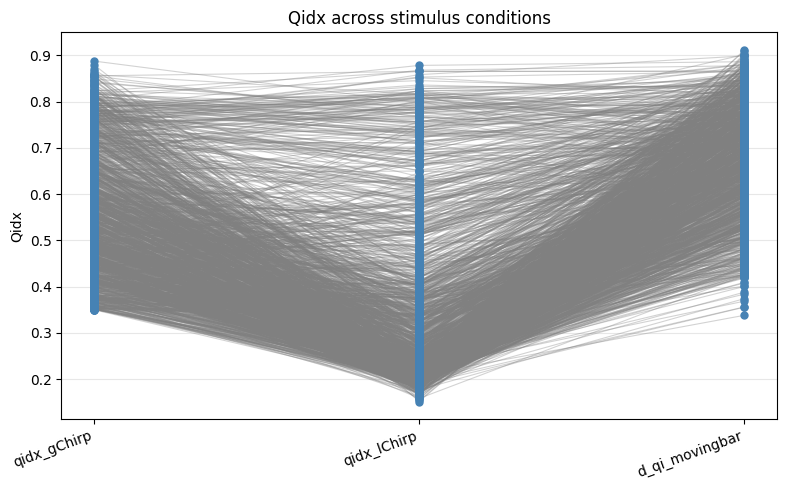

In [11]:
columns = ["qidx_gChirp", "qidx_lChirp", "d_qi_movingbar"]

# Extract values as a 2D array
values = df_c1_thresh[columns].to_numpy(dtype=float)
x = np.arange(len(columns))

# Keep only rows without NaN values
valid = np.isfinite(values).all(axis=1)
values = values[valid]

fig, ax = plt.subplots(figsize=(8, 5))

# Plot connecting lines for all rows
ax.plot(x, values.T, color="gray", alpha=0.35, linewidth=0.8)

# Plot scatter points for all rows
ax.scatter(
    np.tile(x, values.shape[0]),
    values.ravel(),
    color="steelblue",
    s=25,
    zorder=2
)

ax.set_xticks(x)
ax.set_xticklabels(columns, rotation=20, ha="right")
ax.set_ylabel("Qidx")
ax.set_title("Qidx across stimulus conditions")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [68]:
def separate_by_qidx(df):

    qidx_gchirp = df["qidx_gChirp"]
    qidx_lchirp = df["qidx_lChirp"]

    # Calculate ratio
    ratio = qidx_gchirp / qidx_lchirp

    threshold = 0.2
    
    if ratio < (1 - threshold):
        return "lchirp"

    elif ratio > (1 + threshold):
        return "gchirp"

    else:
        return "similar"

In [69]:
df_c1_filtered["chirp_group"] = df_c1_filtered.apply(separate_by_qidx, axis=1)

print(f"Global: {len(df_c1_filtered[df_c1_filtered["chirp_group"] == "gchirp"])}")
print(f"Local: {len(df_c1_filtered[df_c1_filtered["chirp_group"] == "lchirp"])}")
print(f"Similar: {len(df_c1_filtered[df_c1_filtered["chirp_group"] == "similar"])}")

all_classified = (len(df_c1_filtered[df_c1_filtered["chirp_group"] == "gchirp"]) + 
                  len(df_c1_filtered[df_c1_filtered["chirp_group"] == "lchirp"]) + 
                  len(df_c1_filtered[df_c1_filtered["chirp_group"] == "similar"]))

print(f"All: {all_classified}")
print(f"OG df: {len(df_c1_filtered)}")

Global: 1336
Local: 103
Similar: 453
All: 1892
OG df: 1892


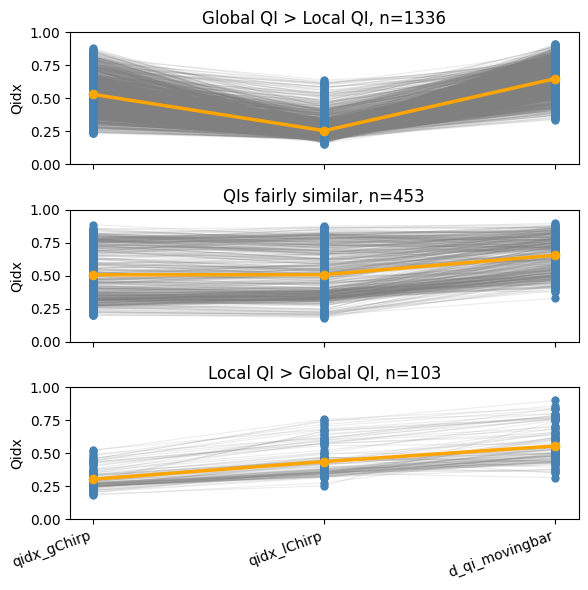

In [74]:

columns = ["qidx_gChirp", "qidx_lChirp", "d_qi_movingbar"]

fig, ax = plt.subplots(3, 1, figsize=(6, 6), sharex=True)

for i, chirp_group in enumerate(groups):

    df_group = df_c1_filtered[
        df_c1_filtered["chirp_group"] == str(chirp_group)
    ]

    # Extract values as a 2D array
    values = df_group[columns].to_numpy(dtype=float)
    x = np.arange(len(columns))

    # Keep only rows without NaN or infinite values
    valid = np.isfinite(values).all(axis=1)
    values = values[valid]

    # Plot connecting lines for all rows
    ax[i].plot(
        x, values.T,
        color="gray",
        alpha=0.15,
        linewidth=0.8
    )

    # Plot scatter points for all rows
    ax[i].scatter(
        np.tile(x, values.shape[0]),
        values.ravel(),
        color="steelblue",
        s=25,
        zorder=2
    )

    # Calculate and plot the mean
    mean_values = values.mean(axis=0)

    ax[i].plot(
        x, mean_values,
        color="orange",
        linewidth=2.5,
        marker="o",
        markersize=6,
        label="Mean",
        zorder=3
    )

    ax[i].set_ylim(0, 1)
    ax[i].set_xticks(x)
    ax[i].set_xticklabels(columns, rotation=20, ha="right")
    ax[i].set_ylabel("Qidx")

    if chirp_group == "lchirp":
        ax[i].set_title(
            f"Local QI > Global QI, n={len(df_group)}"
        )
    elif chirp_group == "gchirp":
        ax[i].set_title(
            f"Global QI > Local QI, n={len(df_group)}"
        )
    else:
        ax[i].set_title(
            f"QIs fairly similar, n={len(df_group)}"
        )

plt.tight_layout()
plt.savefig(f"../plots/qi/qi_scatter_by_chirp_group.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [75]:
df_c1_thresh["chirp_group"] = df_c1_thresh.apply(separate_by_qidx, axis=1)

print(f"Global: {len(df_c1_thresh[df_c1_thresh["chirp_group"] == "gchirp"])}")
print(f"Local: {len(df_c1_thresh[df_c1_thresh["chirp_group"] == "lchirp"])}")
print(f"Similar: {len(df_c1_thresh[df_c1_thresh["chirp_group"] == "similar"])}")

all_classified = (len(df_c1_thresh[df_c1_thresh["chirp_group"] == "gchirp"]) + 
                  len(df_c1_thresh[df_c1_thresh["chirp_group"] == "lchirp"]) + 
                  len(df_c1_thresh[df_c1_thresh["chirp_group"] == "similar"]))

print(f"All: {all_classified}")
print(f"OG df: {len(df_c1_thresh)}")

Global: 1200
Local: 23
Similar: 314
All: 1537
OG df: 1537


/tmp/ipykernel_416328/1900983569.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_c1_thresh["chirp_group"] = df_c1_thresh.apply(separate_by_qidx, axis=1)


In [76]:
groups = df_c1_thresh["chirp_group"].unique()
for i in groups:
    print(i)

gchirp
similar
lchirp


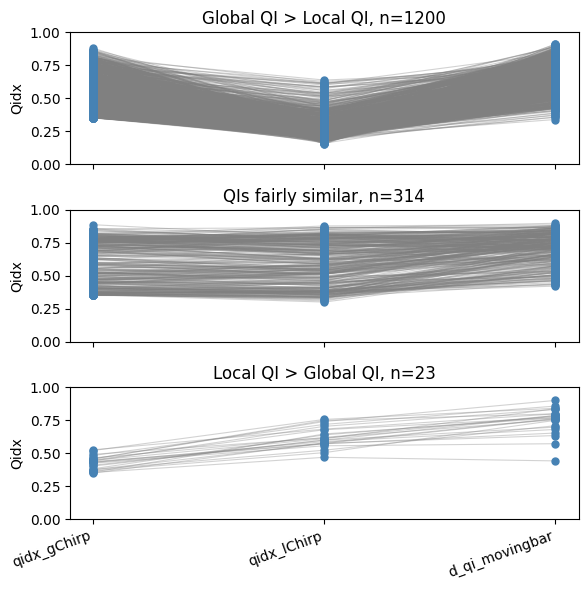

In [77]:
columns = ["qidx_gChirp", "qidx_lChirp", "d_qi_movingbar"]

fig, ax = plt.subplots(3,1, figsize=(6,6), sharex=True)

for i, chirp_group in enumerate(groups):

    df_group = df_c1_thresh[df_c1_thresh["chirp_group"] == str(chirp_group)]

    # Extract values as a 2D array
    values = df_group[columns].to_numpy(dtype=float)
    x = np.arange(len(columns))
    
    # Keep only rows without NaN values
    valid = np.isfinite(values).all(axis=1)
    values = values[valid]
    
    # Plot connecting lines for all rows
    ax[i].plot(x, values.T, color="gray", alpha=0.35, linewidth=0.8)
    
    # Plot scatter points for all rows
    ax[i].scatter(
        np.tile(x, values.shape[0]),
        values.ravel(),
        color="steelblue",
        s=25,
        zorder=2
    )

    ax[i].set_ylim(0,1)
    ax[i].set_xticks(x)
    ax[i].set_xticklabels(columns, rotation=20, ha="right")
    ax[i].set_ylabel("Qidx")

    if chirp_group == "lchirp":
        ax[i].set_title(f"Local QI > Global QI, n={len(df_group)}")

    elif chirp_group == "gchirp":
        ax[i].set_title(f"Global QI > Local QI, n={len(df_group)}")

    else:
        ax[i].set_title(f"QIs fairly similar, n={len(df_group)}")

plt.tight_layout()
plt.savefig(f"../plots/qi/qi_scatter_by_chirp_group_threshold.png",
            dpi=300,
            bbox_inches="tight")
plt.show()